In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import geopandas as gpd
import folium

df = pd.read_csv('../data/curated/town_distance_data.csv', index_col=[0])

/Users/seamus/opt/anaconda3/envs/adsenv/lib/python3.10/site-packages/geopandas/_compat.py:124: UserWarning: The Shapely GEOS version (3.11.1-CAPI-1.17.1) is incompatible with the GEOS version PyGEOS was compiled with (3.10.4-CAPI-1.16.2). Conversions between both will be slow.
  warnings.warn(
/var/folders/sd/77knmvss2x77fx4zk026v8_m0000gn/T/ipykernel_92527/358212660.py:5: DeprecationWarning: Shapely 2.0 is installed, but because PyGEOS is also installed, GeoPandas still uses PyGEOS by default. However, starting with version 0.14, the default will switch to Shapely. To force to use Shapely 2.0 now, you can either uninstall PyGEOS or set the environment variable USE_PYGEOS=0. You can do this before starting the Python process, or in your code before importing geopandas:

import os
os.environ['USE_PYGEOS'] = '0'
import geopandas

In the next release, GeoPandas will switch to using Shapely by default, even if PyGEOS is installed. If you only have PyGEOS installed to get speed-ups, this sw

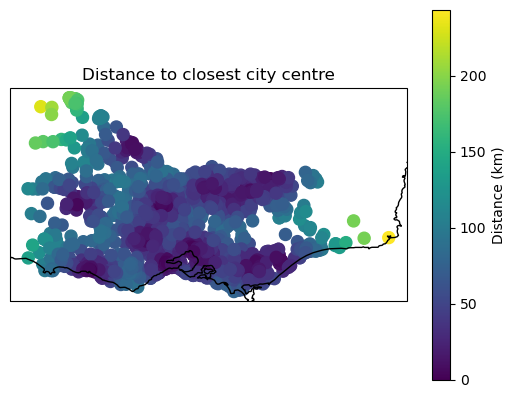

In [3]:
# These first two are matplotlib

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})

# Plotting the data points
sc = ax.scatter(df['lng'], df['lat'], c=df['closest_cc_dist'], cmap='viridis', s=75, transform=ccrs.PlateCarree())


# Adding a colorbar
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Distance (km)')

# Add other map elements like coastlines, gridlines, and labels if needed
ax.coastlines()

# Set the title
ax.set_title('Distance to closest city centre')

plt.savefig('../plots/distance_to_closest_city_centre.png', dpi=200)

In [4]:
q = df[df['city_centre']==True][['name', 'lat', 'lng']]
idx = df[df['city_centre']==True]['name'].drop_duplicates().index
main_cities = q.loc[idx].reset_index().drop(columns='index')
main_cities

,name,lat,lng
0,Ballarat,-37.56266,143.85038
1,Benalla,-36.55397,145.97985
2,Bendigo,-36.75814,144.27863
3,Cranbourne,-38.10243,145.27776
4,Geelong,-38.14985,144.36188
5,Horsham,-36.71555,142.19756
6,Melbourne,-37.81302,144.96111
7,Morwell,-38.23072,146.41448
8,Sale,-38.10286,147.07451
9,Shepparton,-36.37909,145.40432


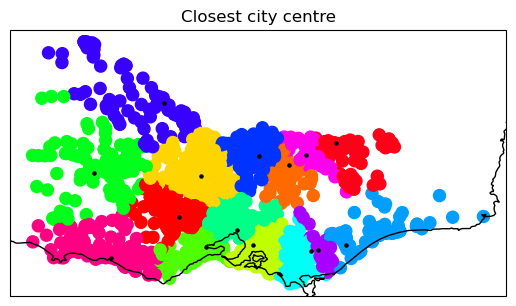

In [5]:
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})

sc = ax.scatter(df['lng'], df['lat'], c=df['closest_city_centre'].astype('category').cat.codes, cmap='hsv', s=75, transform=ccrs.PlateCarree())

# Plotting the data points
for i, txt in enumerate(main_cities['name']):
    ax.scatter(main_cities['lng'][i], main_cities['lat'][i], c='black', s=5)
    #ax.annotate(txt, (main_cities['lng'][i], main_cities['lat'][i]), fontsize=8, arrowprops=dict(facecolor='black'), transform=ccrs.PlateCarree())

# Add other map elements like coastlines, gridlines, and labels if needed
ax.coastlines()

# Set the title
ax.set_title('Closest city centre')

#plt.show()
plt.savefig('../plots/closest_city_centre.png', dpi=400)